# Individual homework project 1

In [123]:
import pandas as pd 


In [124]:
customers = pd.read_csv("customers.csv")
transactions = pd.read_csv("transactions.csv")
campaign_touchpoints = pd.read_csv("campaign_touchpoints.csv")
web_sessions = pd.read_csv("web_sessions.csv")

### Specific questions

Q1. What is the average purchase value for customers from Spain?

In [125]:
print(customers.columns.tolist())
print(transactions.columns.tolist())
for col in transactions.columns:
    print(col)
    merged = transactions.merge(customers, on="customer_id")
spain_avg = merged.loc[merged["country"] == "Spain", "purchase_value"].mean()
spain_avg

['customer_id', 'age', 'gender', 'country', 'acquisition_channel', 'signup_date', 'customer_status', 'loyalty_tier', 'campaign_id', 'last_active_date']
['transaction_id', 'customer_id', 'product_category', 'purchase_value', 'discount_used', 'purchase_date', 'is_refunded', 'refund_date', 'refund_reason']
transaction_id
customer_id
product_category
purchase_value
discount_used
purchase_date
is_refunded
refund_date
refund_reason


np.float64(230.95889872521244)

Q2. What is the minimum purchase value for customers from Germany?

In [126]:
germany_min = merged.loc[merged["country"] == "Germany", "purchase_value"].min()
germany_min

np.float64(10.01)

Q3. How much did males spend on buying products in the Sports category?

In [127]:
male_sports_spend = merged.loc[
    (merged["gender"] == "Male") & (merged["product_category"] == "Sports"),
    "purchase_value"
].sum()

male_sports_spend
print(customers["gender"].unique())
print(transactions["product_category"].unique())
merged[(merged["gender"] == "Male") & (merged["product_category"] == "Sports")][["customer_id", "gender", "product_category", "purchase_value"]]

<StringArray>
['Other', 'Female', 'Male']
Length: 3, dtype: str
<StringArray>
['home', 'fashion', 'toys', 'electronics', 'sports', 'beauty']
Length: 6, dtype: str


,customer_id,gender,product_category,purchase_value


Q4. What is the average age of female customers from Canada?

In [128]:
canada_female_avg_age = customers.loc[
    (customers["gender"] == "Female") & (customers["country"] == "Canada"),
    "age"
].mean()

canada_female_avg_age

np.float64(42.9168765743073)

Q5. How much does an average male customer from the UK spend?

In [129]:
uk_male_avg_spend = merged.loc[
    (merged["gender"] == "Male") & (merged["country"] == "UK"),
    "purchase_value"
].mean()

uk_male_avg_spend

np.float64(234.48157309322036)

Q6. What is the maximum purchase value for females in the Toys category?

In [130]:
female_toys_max = merged.loc[
    (merged["gender"] == "Female") & (merged["product_category"] == "Toys"),
    "purchase_value"
].max()

female_toys_max
merged[
    (merged["gender"] == "Female") &
    (merged["product_category"] == "Toys")
][["gender", "product_category", "purchase_value"]]

,gender,product_category,purchase_value


Q7. What is the average number of pages viewed for customers who made a purchase (converted)?

In [131]:
avg_pages_converted = web_sessions.loc[
    web_sessions["converted"] == True,
    "pages_viewed"
].mean()

avg_pages_converted


np.float64(5.728619675345898)

Q8. What is the average time spent on the site for purchasing vs non-purchasing customers?

In [132]:
web_sessions.groupby("converted")["time_on_site"].mean()

converted
0    299.238547
1    311.194837
Name: time_on_site, dtype: float64

### Visualisation tasks

Q9. Plot purchasing value across years.

<Axes: title={'center': 'Purchase Value Across Years'}, xlabel='purchase_date'>

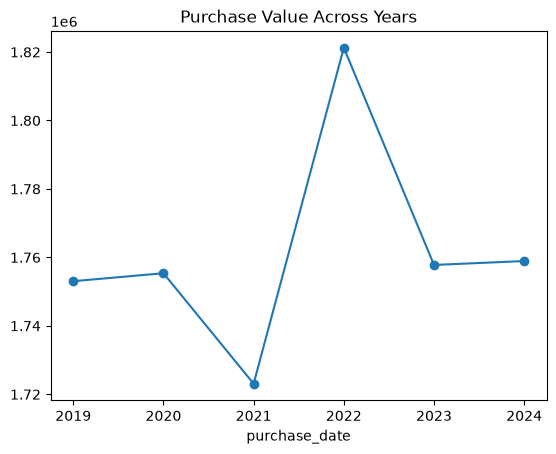

In [133]:
transactions["purchase_date"] = pd.to_datetime(transactions["purchase_date"])

yearly_purchase = transactions.groupby(
    transactions["purchase_date"].dt.year
)["purchase_value"].sum()

yearly_purchase.plot(kind="line", marker="o", title="Purchase Value Across Years")

Q10. Plot purchasing value across product categories.

<Axes: title={'center': 'Purchase Value Across Product Categories'}, xlabel='product_category'>

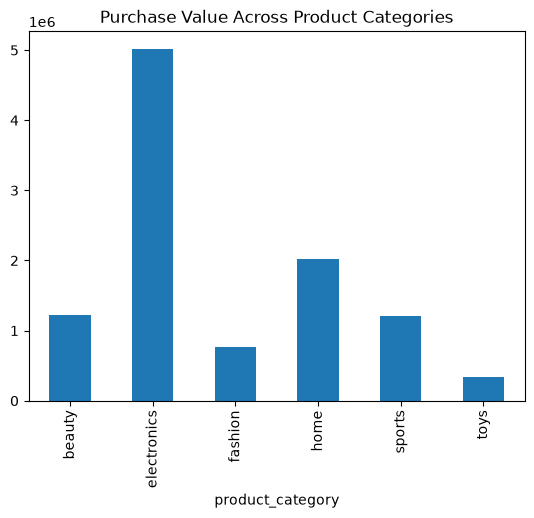

In [134]:
category_purchase = transactions.groupby("product_category")["purchase_value"].sum()

category_purchase.plot(
    kind="bar",
    title="Purchase Value Across Product Categories"
)

### Free exercise

Explore the transactions dataset and:

- Create two visualisations of your choice
- Identify three patterns in the data
- Write five insights in plain English explaining what the data tells us

Your insights should focus on behaviour, spending patterns, or conversion

<Axes: title={'center': 'Refunded vs Non-Refunded Transactions'}>

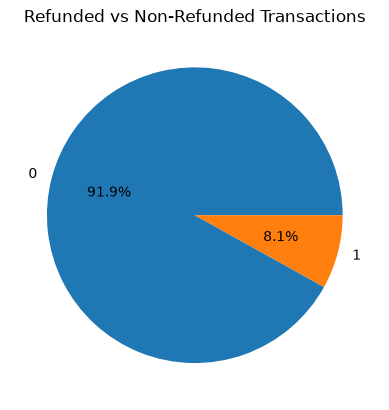

In [135]:
refund_counts = transactions["is_refunded"].value_counts()

refund_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Refunded vs Non-Refunded Transactions"
)


<Axes: title={'center': 'Distribution of Purchase Values'}, ylabel='Frequency'>

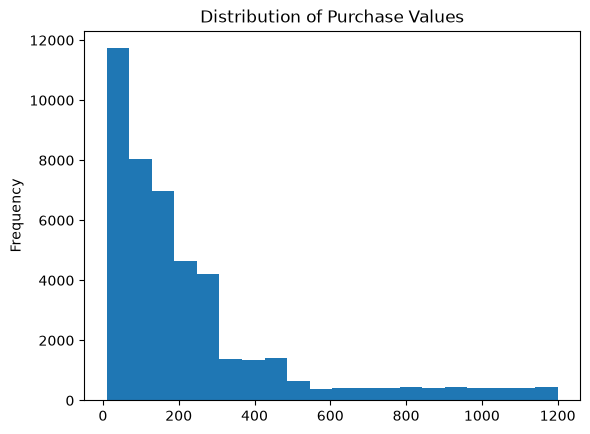

In [136]:
transactions["purchase_value"].plot(
    kind="hist",
    bins=20,
    title="Distribution of Purchase Values"
)

### Patterns

1. Most purchases are on the lower side, and very expensive purchases are less common.
2. Only a small number of transactions were refunded.
3. The total purchase value was highest in 2022.

### Insights

1. Customers mostly spend smaller amounts.
2. Very high-value purchases happen less often.
3. Most customers did not ask for a refund.
4. Sales were strongest in 2022.
5. The spending pattern is not equal across all transactions.